# CleanAir Routes — [FAVELA_IBM Z Datathon 2026 Project]

**Forecast PM2.5 across Chennai for the next 24 hours, then tell people which way and when to travel so they breathe in the least pollution.**

This notebook was run on our **IBM LinuxONE** VM (LinuxONE Community Cloud). Every output below was produced on the IBM Z machine:

1. Platform: proof we run on IBM Z (s390x, z17 AI accelerator)
2. Data: the real Chennai monitoring data
3. Forecast model: results on data the model never saw
4. IBM z17 AI accelerator: CPU vs NNPA benchmark
5. A route for an asthma patient, the evening before a pollution spike
6. Health officials' outlook and alerts
7. IBM Granite GenAI on LinuxONE (optional, about 1 minute)

Team FAVELA · Event code SSF2026 · Code: https://github.com/meranjith28/FAVELA-CleanAir-Routes-IBMZ-Datathon-2026

In [24]:
import os, json, platform, subprocess
for d in ('~/cleanair', '/home/ibm-user/cleanair'):   # project folder on the LinuxONE VM
    if os.path.exists(os.path.join(os.path.expanduser(d), 'src')): os.chdir(os.path.expanduser(d)); break
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 160)

## 1 · Platform: IBM LinuxONE (IBM Z)

In [25]:
print('Machine architecture :', platform.machine())
print('Python               :', platform.python_version())
lscpu = subprocess.run(['lscpu'], capture_output=True, text=True).stdout
print('\n'.join(l for l in lscpu.splitlines() if l.split(':')[0] in ('Architecture','Vendor ID','Machine type','CPU(s)','Byte Order')))
cpuinfo = open('/proc/cpuinfo').read() if os.path.exists('/proc/cpuinfo') else ''
print('On-chip AI accelerator (NNPA) flag:', 'nnpa' in cpuinfo.split())

Machine architecture : s390x
Python               : 3.12.15
Architecture:                            s390x
Byte Order:                              Big Endian
CPU(s):                                  3
Vendor ID:                               IBM/S390
Machine type:                            9175
On-chip AI accelerator (NNPA) flag: True


## 2 · Data: real Chennai monitoring stations

Hourly PM2.5 from CPCB / TNPCB stations and the US Consulate monitor (via the OpenAQ API), plus Open-Meteo weather, all downloaded automatically on this VM by `src/fetch.py`.

In [26]:
from src.data import load_processed
pm, weather = load_processed()
summary = pm.groupby('station').agg(first=('time','min'), last=('time','max'),
                                    hours=('pm25','count'), mean_pm25=('pm25','mean')).round({'mean_pm25': 1})
print(f'{len(summary)} stations, {len(pm):,} station-hours, {len(weather):,} weather hours')
summary

8 stations, 125,582 station-hours, 24,528 weather hours


,first,last,hours,mean_pm25
station,,,,
Arumbakkam,2025-02-19 01:00:00,2026-10-13 23:00:00,10729,35.2
Chennai,2024-01-01 05:00:00,2026-10-16 01:00:00,15121,30.0
Kodungaiyur,2025-02-19 01:00:00,2026-10-13 23:00:00,12484,31.8
Manali,2025-02-19 01:00:00,2026-10-13 23:00:00,12356,32.3
Manali Village,2025-02-19 01:00:00,2026-10-13 23:00:00,13317,28.3
Perungudi,2025-02-19 01:00:00,2026-10-13 23:00:00,12987,33.2
Royapuram,2025-02-19 01:00:00,2026-10-13 23:00:00,11990,25.9
Velachery Res. Area,2025-02-19 01:00:00,2026-10-13 23:00:00,12693,29.3


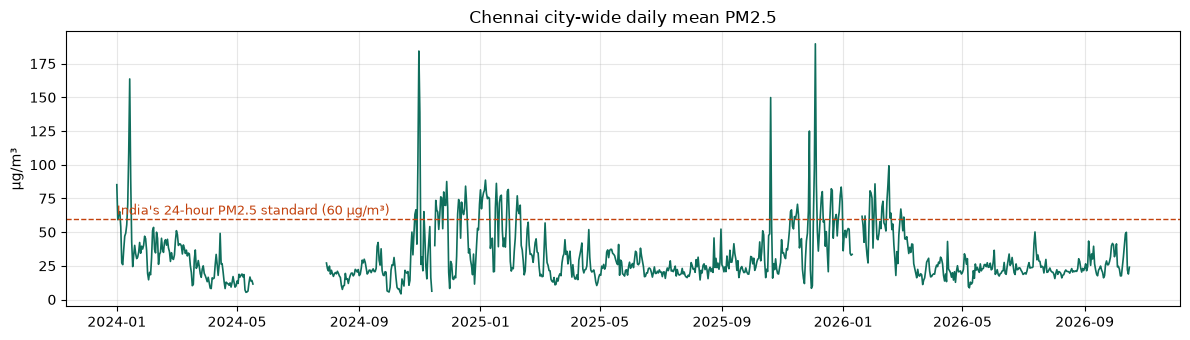

In [27]:
city = pm.groupby('time')['pm25'].mean().resample('D').mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(city.index, city.values, color='#0F6E5C', lw=1.2)
ax.axhline(60, color='#C2410C', ls='--', lw=1)
ax.text(city.index[0], 63, "India's 24-hour PM2.5 standard (60 µg/m³)", color='#C2410C', fontsize=9)
ax.set_title('Chennai city-wide daily mean PM2.5'); ax.set_ylabel('µg/m³'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3 · Forecast model: tested on data it never saw

One gradient-boosting model per horizon, blended with the 'no change' forecast (weight chosen on a validation slice), plus a calibrated 90th-percentile worst case. Test period: Chennai's polluted winter, held out with 72-hour buffers.

In [28]:
m = json.load(open('reports/metrics.json'))
print('Held-out test period:', m.get('test_label'), '| trained on', m['platform']['machine'])
rows = []
for h, v in m['horizons'].items():
    rows.append({'horizon': f'+{h} h', 'no-change error': v['persistence']['MAE'],
                 'our error': v['hybrid']['MAE'], 'better by %': v['skill_vs_persistence_%'],
                 'worst-case coverage': v['p90_coverage'], 'train seconds': v['train_seconds']})
res = pd.DataFrame(rows); res

Held-out test period: 01 Dec 2025 - 28 Feb 2026 | trained on s390x


,horizon,no-change error,our error,better by %,worst-case coverage,train seconds
0,+1 h,10.69,10.34,3.3,0.921,2.0
1,+3 h,18.41,16.36,11.1,0.912,2.0
2,+6 h,23.18,19.24,17.0,0.912,2.1
3,+12 h,26.17,22.66,13.4,0.914,2.1
4,+24 h,24.10,23.62,2.0,0.846,2.1


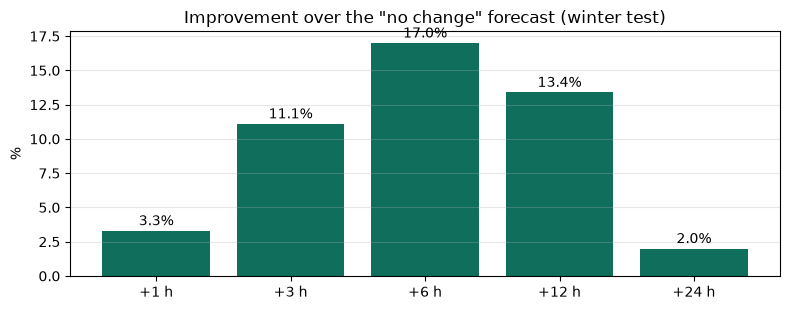

Between-station estimate (leave-one-station-out): weighting power 0.0 | MAE by power: {'0.0': 26.22, '0.5': 28.04, '1.0': 30.23, '2.0': 32.82, '3.0': 34.18}


In [29]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(res['horizon'], res['better by %'], color='#0F6E5C')
for i, v in enumerate(res['better by %']): ax.text(i, v + .4, f'{v}%', ha='center')
ax.set_title('Improvement over the "no change" forecast (winter test)'); ax.set_ylabel('%'); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()
print('Between-station estimate (leave-one-station-out): weighting power', m['loso']['best_power'],
      '| MAE by power:', {p: v['MAE'] for p, v in m['loso']['by_power'].items()})

## 4 · IBM z17 Integrated Accelerator for AI (NNPA)

A neural forecaster is run on the CPU and on the on-chip AI accelerator via `torch_nnpa`. Full run: `python3 scripts/nnpa_benchmark.py 1 6 24`.

In [30]:
try:
    import torch, torch_nnpa
    x = torch.randn(256, 256)
    y = (x.to('nnpa') @ x.to('nnpa')).to('cpu')
    print('torch', torch.__version__, '| matrix multiply on NNPA OK, max diff vs CPU:',
          float((y - x @ x).abs().max()))
except Exception as e:
    print('NNPA not available here:', e)
if not os.path.exists('reports/nnpa_benchmark.json'):
    print('Run: python3 scripts/nnpa_benchmark.py 1 6 24')
else:
  b = json.load(open('reports/nnpa_benchmark.json'))
  display(pd.DataFrame([{'horizon': f"+{r['horizon_h']} h", 'no-change MAE': r['mae_persistence'],
               'CPU MAE': r['cpu']['mae'], 'NNPA MAE': r['nnpa'].get('mae'),
               'CPU ms (test set)': r['cpu']['batch_ms'], 'NNPA ms (test set)': r['nnpa'].get('batch_ms'),
               'speed-up': r.get('nnpa_speedup_batch'),
               'avg diff µg/m³': r['nnpa'].get('mean_abs_diff_vs_cpu_ug_m3')} for r in b['runs']]))

torch 2.11.0+cpu | matrix multiply on NNPA OK, max diff vs CPU: 0.1835174560546875


,horizon,no-change MAE,CPU MAE,NNPA MAE,CPU ms (test set),NNPA ms (test set),speed-up,avg diff µg/m³
0,+1 h,10.52,10.13,10.13,8.79,0.38,23.18,0.0153
1,+6 h,23.62,20.54,20.56,8.29,0.41,20.07,0.0646
2,+24 h,24.67,25.27,25.30,7.91,0.39,20.12,0.0800


## 5 · A route for an asthma patient

7 pm on 20 Dec 2025, the evening before a winter spike, a moment inside the held-out test period. The forecaster only sees readings up to that hour.

In [31]:
import time
from src.model import Forecaster
from src.routing import Router, available_areas
now = pd.Timestamp('2025-12-20 19:00')
t = time.time(); fc = Forecaster().forecast(pm, weather, now); t_fc = time.time() - t
print(f'Forecast for {len(fc)} stations in {t_fc:.2f} s')
pd.DataFrame({st: {'now': v['median'][0], '+6 h': v['median'][6], '+12 h': v['median'][12],
                   '+12 h worst case': v['p90'][12]} for st, v in fc.items()}).T.round(1)

Forecast for 7 stations in 0.60 s


,now,+6 h,+12 h,+12 h worst case
Arumbakkam,107.0,95.3,123.2,197.2
Kodungaiyur,123.0,123.9,100.2,198.9
Manali,94.0,67.1,66.5,134.1
Manali Village,92.1,92.2,98.3,160.2
Perungudi,98.7,90.9,149.5,197.6
Royapuram,83.1,37.2,46.2,82.0
Velachery Res. Area,7.7,13.2,20.1,33.4


In [32]:
router = Router(available_areas()[0])
start, dest = (13.0820, 80.2420), (13.0600, 80.2430)       # Kilpauk -> Nungambakkam
t = time.time()
router.set_pollution({st: v['p90'][0] for st, v in fc.items()}, 'walk')   # asthma: worst-case forecast
r = router.routes(start, dest)
best = []
for h in range(25):
    d, c = router.dose_along(r['cleanest']['_path'], {st: v['p90'][h] for st, v in fc.items()}, 'walk')
    best.append((h, d))
print(f'3 routes + 24-hour profile in {time.time() - t:.2f} s on {router.G.number_of_nodes():,} junctions')
display(pd.DataFrame({k: {'minutes': v['minutes'], 'km': v['km'], 'avg PM2.5': v['avg_pm25'],
                          'inhaled µg': v['dose_ug']} for k, v in r.items()}).T)
h, d = min(best, key=lambda x: x[1])
print(f'Lowest-exposure departure: {now + pd.Timedelta(hours=h):%a %H:%M} ({d:.0f} µg vs {best[0][1]:.0f} µg leaving now)')

3 routes + 24-hour profile in 0.19 s on 120,566 junctions


,minutes,km,avg PM2.5,inhaled µg
fastest,38.2,3.06,94.2,84.08
cleanest,38.3,3.06,91.4,81.66
balanced,38.3,3.06,91.4,81.66


Lowest-exposure departure: Sat 19:00 (82 µg vs 82 µg leaving now)


## 6 · Health officials' 24-hour outlook

In [33]:
from src import officials
o = officials.build(fc, now, 'en')
s = o['summary']
print(f"{s['stations_poor']} of {s['stations']} stations expected to reach Poor or worse in the next 24 h")
print(f"First Poor hour: {s['first_poor']} | worst: {s['worst_station']} {s['worst_peak']} µg/m³ ({s['worst_cat']}) at {s['worst_time']}")
print(f"{s['n_alerts']} ready-to-send public alerts. Top 3:")
for a in o['alerts'][:3]:
    print('\n-', a['text'])

5 of 7 stations expected to reach Poor or worse in the next 24 h
First Poor hour: Sat 20:00 | worst: Perungudi 149.5 µg/m³ (Very Poor) at Sun 07:00
8 ready-to-send public alerts. Top 3:

- Arumbakkam area: Very Poor air expected Sat 20:00 to Sun 20:00. Peak PM2.5 about 123 µg/m³ around Sun 07:00. Everyone should avoid outdoor exertion. Schools: cancel outdoor activities. Issue a public health advisory and check local traffic and industrial emission sources.

- Kodungaiyur area: Very Poor air expected Sat 20:00 to Sun 20:00. Peak PM2.5 about 129 µg/m³ around Sat 20:00. Everyone should avoid outdoor exertion. Schools: cancel outdoor activities. Issue a public health advisory and check local traffic and industrial emission sources.

- Perungudi area: Very Poor air expected Sat 20:00 to Sun 20:00. Peak PM2.5 about 150 µg/m³ around Sun 07:00. Everyone should avoid outdoor exertion. Schools: cancel outdoor activities. Issue a public health advisory and check local traffic and industrial emis

## 7 · IBM Granite GenAI on LinuxONE (optional)

IBM Granite 3.3 2B (big-endian build) runs locally through llama.cpp. On 3 vCPUs one answer takes about a minute, so this cell is off by default: set `RUN_GRANITE = True` to run it.

In [34]:
RUN_GRANITE = False
if RUN_GRANITE:
    os.environ.setdefault('LOCAL_GGUF', os.path.expanduser('~/granite-3.3-2b-instruct-be.Q4_K_M.gguf'))
    from src.advisory import llm_explain, guidance
    adv = guidance('asthma', r['balanced']['avg_pm25'], r['balanced']['avg_pm25'])
    t = time.time()
    out = llm_explain({'traveller': 'Asthma / respiratory', 'aqi': adv['aqi'], 'category': adv['category'],
                       'rule_based_advice': adv['text'],
                       'best_time_to_leave': f'{now + pd.Timedelta(hours=h):%a %H:%M}'}, 'en')
    print(f'{time.time() - t:.0f} s ->', out['text'] if out else 'no answer')

## Summary

- Runs entirely on **IBM LinuxONE (IBM z17, s390x)**: data download, training, forecasting, routing, serving (Docker container).
- Forecast beats "no change" at every horizon on a held-out winter, with a calibrated worst case for sensitive users.
- Neural forecaster on the **z17 on-chip AI accelerator**: same results as the CPU, much faster.
- Local **IBM Granite** GenAI: no user data leaves the machine.